# Homogeneity (change-point) tests on the NASA POWER inputs, plus a raw-rainfall baseline

Addresses the data-validation requests (Reviewer 1 comment 11, Reviewer 2 comment 8, Reviewer 3 comment 3) and checks whether the large shifts at Abuja and Jalingo could be artefacts of the reanalysis products.

**Tests (annual series, 1981-2022; radiation from 1984):** Pettitt, SNHT (Alexandersson) and Buishand range test, with **permutation p-values** (no normality assumption). Each is run on the raw series and on the **linearly detrended** series, because a steady trend makes these tests flag a change point near the middle of the record even when there is no abrupt break.

**Variables:** annual precipitation total, mean/max/min temperature, relative humidity, wind speed, solar radiation (Penman-Monteith inputs).

**Reading the output:** with 8 sites x 7 variables = 56 series, about 3 would be flagged at p < 0.05 by chance alone, so Benjamini-Hochberg adjusted p-values are also given.

Needs `reshaped_climate_data.xlsx` and `extra_variables.xlsx` in the same folder.

In [1]:
import os, numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
DATA, XV, OUT = 'reshaped_climate_data.xlsx', 'extra_variables.xlsx', 'homogeneity_outputs'
os.makedirs(OUT, exist_ok=True); NPERM = 5000; SEED = 2026; rng = np.random.default_rng(SEED)

P = pd.read_excel(DATA, 'Precip_Wide', index_col='Date').drop(columns=['Year', 'Month'], errors='ignore')
T = pd.read_excel(DATA, 'Temp_Wide', index_col='Date').drop(columns=['Year', 'Month'], errors='ignore')
ex = {s: pd.read_excel(XV, s, index_col='Date') for s in ('Tmax', 'Tmin', 'RH', 'Wind', 'Srad')}
for d in [P, T, *ex.values()]: d.index = pd.to_datetime(d.index)

def annual(df, how):
    g = df.groupby(df.index.year); out = g.sum(min_count=12) if how == 'sum' else g.mean()
    cnt = g.count(); return out.where(cnt >= 12)          # require 12 valid months
VARS = {'Precipitation (mm/yr)': annual(P, 'sum'), 'Mean temperature (C)': annual(T, 'mean'), 'Tmax (C)': annual(ex['Tmax'], 'mean'),
        'Tmin (C)': annual(ex['Tmin'], 'mean'), 'Relative humidity (%)': annual(ex['RH'], 'mean'), 'Wind speed (m/s)': annual(ex['Wind'], 'mean'),
        'Solar radiation (MJ/m2/day)': annual(ex['Srad'], 'mean')}
print({k: (int(v.dropna(how='all').index.min()), int(v.dropna(how='all').index.max())) for k, v in VARS.items()})

{'Precipitation (mm/yr)': (1981, 2022), 'Mean temperature (C)': (1981, 2022), 'Tmax (C)': (1981, 2022), 'Tmin (C)': (1981, 2022), 'Relative humidity (%)': (1981, 2022), 'Wind speed (m/s)': (1981, 2022), 'Solar radiation (MJ/m2/day)': (1984, 2022)}


In [2]:
# ---------- permutation-based change-point tests (vectorised over permutations)
def stat_pettitt(R):                       # R: (m, n) ranks
    n = R.shape[1]; t = np.arange(1, n + 1); U = 2 * np.cumsum(R, axis=1) - t * (n + 1)
    a = np.abs(U[:, :-1]); return a.max(axis=1), a.argmax(axis=1) + 1          # change after position k
def stat_snht(Z):
    n = Z.shape[1]; k = np.arange(1, n); c = np.cumsum(Z, axis=1)[:, :-1]
    m1 = c / k; m2 = (c[:, -1:] * 0 + Z.sum(axis=1, keepdims=True) - c) / (n - k)
    Tk = k * m1 ** 2 + (n - k) * m2 ** 2; return Tk.max(axis=1), Tk.argmax(axis=1) + 1
def stat_buishand(Z):
    S = np.cumsum(Z - Z.mean(axis=1, keepdims=True), axis=1); r = (S.max(axis=1) - S.min(axis=1)); 
    kk = np.abs(S).argmax(axis=1) + 1; return r, kk

def run_tests(x):
    x = np.asarray(x, float); n = len(x); out = {}
    ranks = stats.rankdata(x); z = (x - x.mean()) / x.std(ddof=1)
    perms = rng.permuted(np.tile(np.arange(n), (NPERM, 1)), axis=1)
    for name, fn, base in (('Pettitt', stat_pettitt, ranks), ('SNHT', stat_snht, z), ('Buishand', stat_buishand, z)):
        s0, k0 = fn(base[None, :]); sp, _ = fn(base[perms])
        out[name] = dict(p=(1 + (sp >= s0[0]).sum()) / (NPERM + 1), k=int(k0[0]))
    return out

def detrend(x, years):
    sl = stats.theilslopes(x, years)[0]; r = x - sl * (years - years.mean()); return r - r.mean() + x.mean()

rows = []
for var, df in VARS.items():
    for loc in P.columns:
        s = df[loc].dropna(); yrs = s.index.values.astype(float); x = s.values
        for kind, series in (('raw', x), ('detrended', detrend(x, yrs))):
            res = run_tests(series)
            for tname, r in res.items():
                yb = int(yrs[r['k'] - 1]); before, after = x[:r['k']].mean(), x[r['k']:].mean()
                rows.append(dict(Variable=var, Location=loc.title(), series=kind, test=tname, p=r['p'], break_after_year=yb,
                                 mean_before=before, mean_after=after, change=after - before,
                                 change_pct=100 * (after - before) / before if abs(before) > 1e-9 else np.nan, n_years=len(x)))
HT = pd.DataFrame(rows)
# Benjamini-Hochberg adjustment within each (series, test) family
def bh(p):
    p = np.asarray(p); o = np.argsort(p); q = np.empty_like(p); m = len(p); run = 1.0
    for rank, i in zip(range(m, 0, -1), o[::-1]): run = min(run, p[i] * m / rank); q[i] = run
    return q
HT['p_BH'] = HT.groupby(['series', 'test']).p.transform(lambda s: bh(s.values))
print('Series flagged at p<0.05 (unadjusted) / p_BH<0.05, out of', HT[(HT.series == "raw") & (HT.test == "Pettitt")].shape[0])
print(HT.groupby(['series', 'test']).apply(lambda g: pd.Series({'p<0.05': int((g.p < 0.05).sum()), 'BH<0.05': int((g.p_BH < 0.05).sum())})).to_string())

Series flagged at p<0.05 (unadjusted) / p_BH<0.05, out of 56
                    p<0.05  BH<0.05
series    test                     
detrended Buishand      26       19
          Pettitt        0        0
          SNHT          21       14
raw       Buishand      50       50
          Pettitt       41       40
          SNHT          51       50


## Consensus: which series show an abrupt break in at least two of the three tests?

In [3]:
piv = HT.pivot_table(index=['Variable', 'Location', 'series'], columns='test', values=['p', 'break_after_year']).reset_index()
piv.columns = ['_'.join([c for c in col if c]) for col in piv.columns]
piv['n_tests_p<0.05'] = (piv[['p_Pettitt', 'p_SNHT', 'p_Buishand']] < 0.05).sum(axis=1)
meta = HT[HT.test == 'Pettitt'][['Variable', 'Location', 'series', 'change', 'change_pct']]
CONS = piv.merge(meta, on=['Variable', 'Location', 'series'])
flag = CONS[(CONS['n_tests_p<0.05'] >= 2)].copy()
flag['break_year_(Pettitt)'] = flag['break_after_year_Pettitt']
print('Series with p<0.05 in >=2 of 3 tests:')
print(flag.sort_values(['series', 'Variable', 'Location'])[['series', 'Variable', 'Location', 'p_Pettitt', 'p_SNHT', 'p_Buishand', 'break_year_(Pettitt)', 'change', 'change_pct']].round(3).to_string(index=False))
print('\nDo breaks cluster in time across sites? break years (Pettitt, detrended series, p<0.05):')
dd = HT[(HT.test == 'Pettitt') & (HT.series == 'detrended') & (HT.p < 0.05)]
print(dd.groupby('Variable').apply(lambda g: dict(zip(g.Location, g.break_after_year))).to_string())

Series with p<0.05 in >=2 of 3 tests:
   series                    Variable     Location  p_Pettitt  p_SNHT  p_Buishand  break_year_(Pettitt)   change  change_pct
detrended        Mean temperature (C)        Gombe      0.249   0.002       0.005                2015.0   -0.694      -2.558
detrended        Mean temperature (C)       Kukawa      0.315   0.033       0.011                1995.0    0.317       1.028
detrended        Mean temperature (C)       Sokoto      0.156   0.001       0.014                2014.0   -0.966      -3.391
detrended       Precipitation (mm/yr)        Gombe      0.163   0.000       0.014                2015.0  640.100      70.693
detrended       Precipitation (mm/yr) Ikot Akpaden      0.173   0.003       0.029                1997.0 -436.459     -15.430
detrended       Precipitation (mm/yr)       Kukawa      0.291   0.030       0.012                2017.0  256.357      67.903
detrended       Precipitation (mm/yr)       Sokoto      0.146   0.000       0.013      

## Figures: annual precipitation and mean temperature with the Pettitt change point

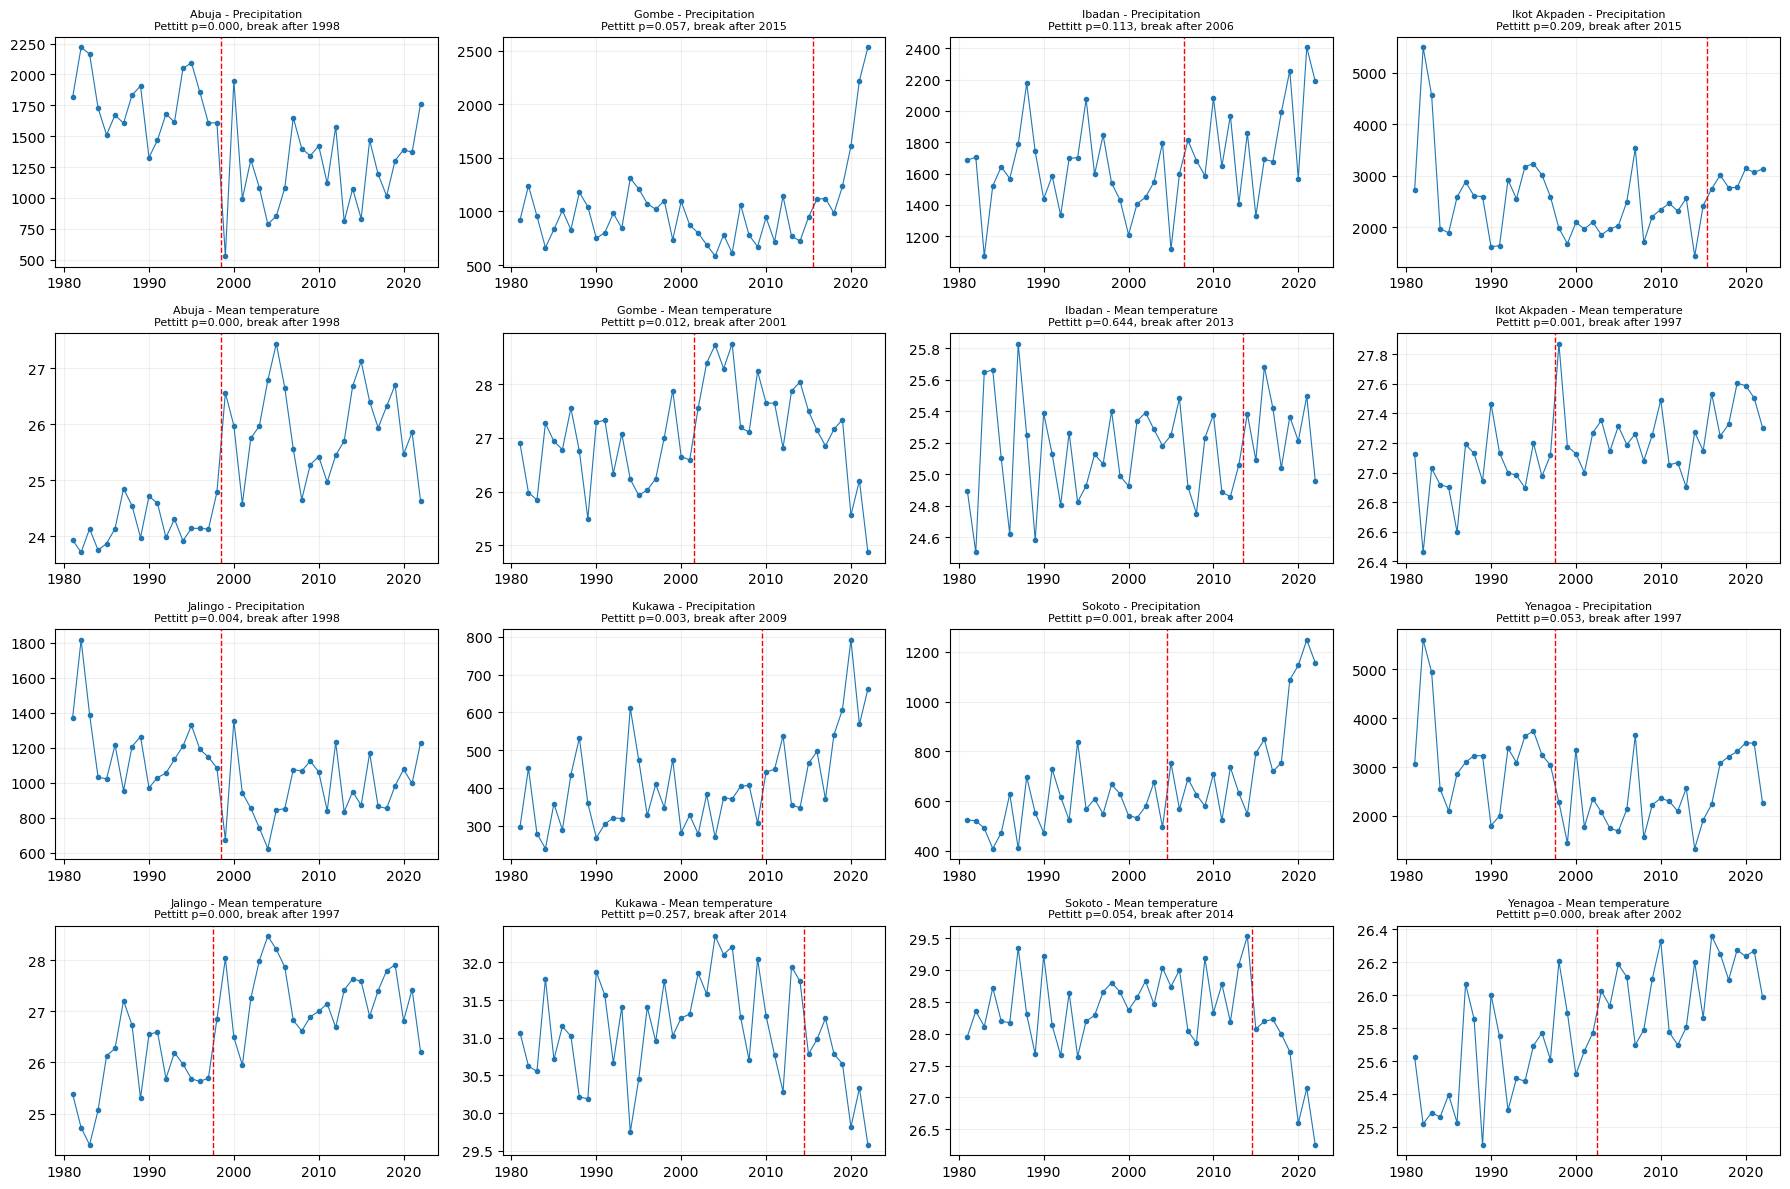

In [4]:
fig, axes = plt.subplots(4, 4, figsize=(18, 12)); order = list(P.columns)
for i, loc in enumerate(order):
    for j, var in enumerate(('Precipitation (mm/yr)', 'Mean temperature (C)')):
        ax = axes[(i // 4) * 2 + j, i % 4]; s = VARS[var][loc].dropna(); ax.plot(s.index, s.values, 'o-', ms=3, lw=0.8)
        r = HT[(HT.Variable == var) & (HT.Location == loc.title()) & (HT.series == 'raw') & (HT.test == 'Pettitt')].iloc[0]
        ax.axvline(r.break_after_year + 0.5, color='red', ls='--', lw=1)
        ax.set_title(f'{loc.title()} - {var.split(" (")[0]}\nPettitt p={r.p:.3f}, break after {int(r.break_after_year)}', fontsize=8)
        ax.grid(alpha=0.2)
plt.tight_layout(); plt.savefig(os.path.join(OUT, 'homogeneity_annual_series.png'), dpi=200); plt.show()

## Raw annual rainfall baseline (1985-2020) - reviewers' benchmark request

In [5]:
def sen_slope(x):
    x = np.asarray(x, float); n = len(x)
    return np.median(np.concatenate([(x[k:] - x[:-k]) / k for k in range(1, n)]))

def mk_test(x, hr=True):
    """Mann-Kendall S, Z, p-value (two-sided) and Sen slope per time step. hr=True applies Hamed & Rao (1998)."""
    x = np.asarray(x, float); n = len(x)
    S = sum(np.sign(x[i + 1:] - x[i]).sum() for i in range(n - 1))
    _, cnt = np.unique(x, return_counts=True)
    var = (n * (n - 1) * (2 * n + 5) - np.sum(cnt * (cnt - 1) * (2 * cnt + 5))) / 18.0
    beta = sen_slope(x); f = 1.0
    if hr:
        r = stats.rankdata(x - beta * np.arange(n)); r = r - r.mean(); den = (r * r).sum()
        lim = stats.norm.ppf(0.975) / np.sqrt(n); sni = 0.0
        for k in range(1, n - 1):
            a = (r[:-k] * r[k:]).sum() / den
            if abs(a) > lim: sni += (n - k) * (n - k - 1) * (n - k - 2) * a
        f = 1 + 2.0 / (n * (n - 1) * (n - 2)) * sni
        f = f if f > 0 else 1.0
    z = 0.0 if S == 0 else (S - np.sign(S)) / np.sqrt(var * f)
    return dict(S=S, Z=z, p=2 * (1 - stats.norm.cdf(abs(z))), sen=beta, vcf=f)

def direction(p, est, alpha=0.05):
    return '0' if not (p < alpha) else ('+' if est > 0 else '-')

In [6]:
ann = VARS['Precipitation (mm/yr)'].loc[1985:2020]; ra = []; rb = np.random.default_rng(SEED)
final = pd.read_excel('SH-ITA_final_PM_results.xlsx', 'Final (primary block)') if os.path.exists('SH-ITA_final_PM_results.xlsx') else None
for loc in ann.columns:
    a = ann[loc].values; m = mk_test(a, hr=True); x1, y1 = a[:18], a[18:]
    diff = y1.mean() - x1.mean(); bs = [rb.choice(y1, 18).mean() - rb.choice(x1, 18).mean() for _ in range(5000)]
    lo, hi = np.percentile(bs, [2.5, 97.5]); d_ita = ('+' if diff > 0 else '-') if (lo > 0 or hi < 0) else '0'
    row = dict(Location=loc.title(), MMK_p=round(m['p'], 3), MMK_dir=('+' if m['sen'] > 0 else '-') if m['p'] < 0.05 else '0',
               Sen_mm_per_decade=round(m['sen'] * 10, 1), ITA_change_mm=round(diff, 1), ITA_pct=round(100 * diff / x1.mean(), 1),
               ITA_CI=f'[{lo:.0f}, {hi:.0f}]', ITA_dir=d_ita)
    if final is not None:
        for idx in ('SPI-12', 'SPEI-12'):
            r = final[(final.Location == loc.title()) & (final.Index == idx)].iloc[0]
            row[idx + '_IISC_dir'] = ('+' if float(r['IISC [95% CI]'].split()[0]) > 0 else '-') if r['IISC clear'] else '0'
    ra.append(row)
RAW = pd.DataFrame(ra); RAW

,Location,MMK_p,MMK_dir,Sen_mm_per_decade,ITA_change_mm,ITA_pct,ITA_CI,ITA_dir,SPI-12_IISC_dir,SPEI-12_IISC_dir
0,Abuja,0.004,-,-171.4,-401.0,-25.2,"[-608, -182]",-,-,-
1,Gombe,0.881,0,9.8,-55.5,-5.7,"[-194, 92]",0,0,0
2,Ibadan,0.522,0,28.9,77.2,4.8,"[-88, 240]",0,0,0
3,Ikot Akpaden,0.481,0,84.5,35.4,1.5,"[-304, 366]",0,0,0
4,Jalingo,0.089,0,-50.5,-142.9,-13.1,"[-243, -34]",-,-,-
5,Kukawa,0.009,+,45.3,66.7,17.9,"[-2, 138]",0,0,0
6,Sokoto,0.001,+,69.3,126.1,21.4,"[41, 215]",+,+,+
7,Yenagoa,0.653,0,-52.0,-370.9,-13.4,"[-798, 78]",0,0,0


## Export

In [7]:
with pd.ExcelWriter(os.path.join(OUT, 'homogeneity_results.xlsx'), engine='openpyxl') as w:
    HT.round(4).to_excel(w, sheet_name='All tests', index=False)
    CONS.round(4).to_excel(w, sheet_name='Consensus (>=2 tests)', index=False)
    RAW.to_excel(w, sheet_name='Raw annual rainfall baseline', index=False)
print('saved to', OUT)

saved to homogeneity_outputs
